In [ ]:
!pip install -q lpips gradio

In [ ]:
import sys, copy, random, zipfile, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from skimage import color as skcolor
from skimage.metrics import structural_similarity as ssim_fn

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

# ------------------------- CONFIG -------------------------
SMOKE_TEST  = False      # True = tiny run (~3 min) just to verify the pipeline
IMG_SIZE    = 256        # training resolution (must be divisible by 32)
BATCH_SIZE  = 16
EPOCHS      = dict(baseline=15, unet=15, gan=15)
PRETRAINED  = True       # ImageNet-pretrained ResNet-34 encoder
NUM_WORKERS = 2
SEED        = 42
USE_DRIVE   = True       # save checkpoints/results to Google Drive (survives disconnects)
MAX_IMAGES  = None       # e.g. 2000 to use fewer images
# ----------------------------------------------------------

if SMOKE_TEST:
    EPOCHS = dict(baseline=1, unet=1, gan=1)
    MAX_IMAGES = 200

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
IN_COLAB = 'google.colab' in sys.modules
print('Device:', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'NO GPU - enable one in Runtime > Change runtime type')

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if DEVICE == 'cuda':
    torch.backends.cudnn.benchmark = True

WORK = Path('/content') if IN_COLAB else Path('./work')
WORK.mkdir(parents=True, exist_ok=True)
CKPT_DIR = WORK / ('ckpt_smoke' if SMOKE_TEST else 'ckpt')
if IN_COLAB and USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        CKPT_DIR = Path('/content/drive/MyDrive/colorization_project') / ('ckpt_smoke' if SMOKE_TEST else 'ckpt')
    except Exception as e:
        print('Drive mount failed, saving locally instead:', e)
CKPT_DIR.mkdir(parents=True, exist_ok=True)
print('Checkpoints ->', CKPT_DIR)

Device: cuda | Tesla T4
Drive mount failed, saving locally instead: Error: credential propagation was unsuccessful
Checkpoints -> /content/ckpt


In [ ]:
DATA_DIR = WORK / 'coco_val2017' / 'val2017'
if not list(DATA_DIR.glob('*.jpg')):
    print('Downloading COCO val2017 (~780 MB)...')
    zip_path = WORK / 'val2017.zip'
    subprocess.run(['wget', '-q', '--show-progress', '-O', str(zip_path),
                    'http://images.cocodataset.org/zips/val2017.zip'], check=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(WORK / 'coco_val2017')
    zip_path.unlink()
all_files = sorted(DATA_DIR.glob('*.jpg'))
print('Images found:', len(all_files))

Images found: 5000


In [ ]:
def is_colorful(path, thr=8.0):
    """Keep only images with real color (drops grayscale / near-grayscale photos)."""
    try:
        with Image.open(path) as im:
            im.draft('RGB', (96, 96))
            a = np.asarray(im.convert('RGB').resize((48, 48)), dtype=np.float32)
        return (np.abs(a[..., 0] - a[..., 1]).mean() + np.abs(a[..., 1] - a[..., 2]).mean()) > thr
    except Exception:
        return False

files = all_files[:MAX_IMAGES] if MAX_IMAGES else all_files
paths = [p for p in tqdm(files, desc='filtering grayscale images') if is_colorful(p)]
random.Random(SEED).shuffle(paths)

N = len(paths)
n_test = max(4, min(500, int(0.10 * N)))
n_val  = max(4, min(300, int(0.06 * N)))
test_paths  = paths[:n_test]
val_paths   = paths[n_test:n_test + n_val]
train_paths = paths[n_test + n_val:]
print(f'Colorful images: {N} -> train {len(train_paths)} | val {len(val_paths)} | test {len(test_paths)}')


class ColorDataset(Dataset):
    """Returns the RGB image as a uint8 tensor (3,H,W). Lab conversion happens on the GPU (fast)."""
    def __init__(self, paths, train):
        self.paths = paths
        if train:
            self.tf = T.Compose([T.RandomResizedCrop(IMG_SIZE, scale=(0.4, 1.0), ratio=(0.75, 1.33)),
                                 T.RandomHorizontalFlip()])
        else:
            self.tf = T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE)])
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = self.tf(Image.open(self.paths[i]).convert('RGB'))
        return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)

def make_loader(ps, train):
    return DataLoader(ColorDataset(ps, train), batch_size=BATCH_SIZE, shuffle=train, drop_last=train,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE == 'cuda'),
                      persistent_workers=(train and NUM_WORKERS > 0))

train_loader = make_loader(train_paths, True)
val_loader   = make_loader(val_paths, False)
test_loader  = make_loader(test_paths, False)

filtering grayscale images:   0%|          | 0/5000 [00:00<?, ?it/s]

Colorful images: 4743 -> train 3985 | val 284 | test 474


max |Lab diff| vs skimage : 0.00018024444580078125
RGB->Lab->RGB round-trip  : 4.511326551437378e-06


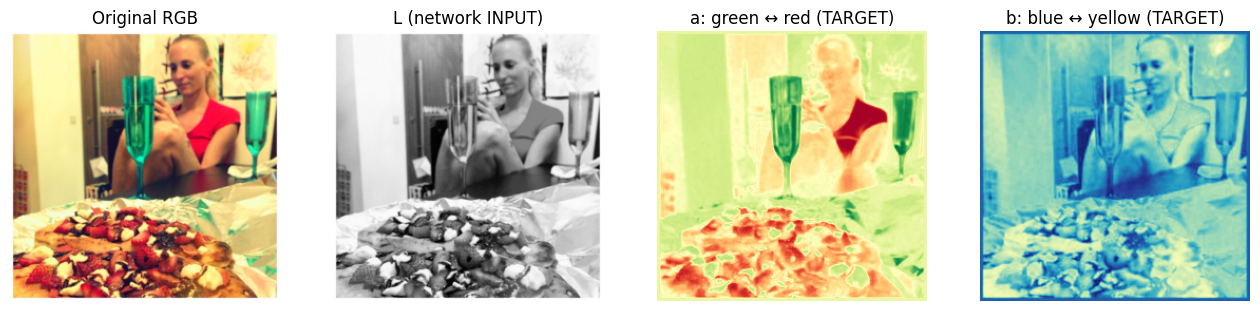

In [ ]:
_M = torch.tensor([[0.412453, 0.357580, 0.180423],
                   [0.212671, 0.715160, 0.072169],
                   [0.019334, 0.119193, 0.950227]], dtype=torch.float32)   # linear sRGB -> XYZ (D65)
_WHITE = torch.tensor([0.95047, 1.0, 1.08883], dtype=torch.float32).view(1, 3, 1, 1)
_EPS, _KAPPA = 216 / 24389, 24389 / 27

def rgb_to_lab(rgb):
    """rgb: (B,3,H,W) in [0,1]  ->  lab: (B,3,H,W) with L in [0,100], a/b in ~[-110,110]."""
    M, W = _M.to(rgb.device), _WHITE.to(rgb.device)
    lin = torch.where(rgb > 0.04045, ((rgb + 0.055) / 1.055).clamp(min=0) ** 2.4, rgb / 12.92)
    xyz = torch.einsum('ij,bjhw->bihw', M, lin) / W
    f = torch.where(xyz > _EPS, xyz.clamp(min=1e-8) ** (1 / 3), (_KAPPA * xyz + 16) / 116)
    L = 116 * f[:, 1] - 16
    a = 500 * (f[:, 0] - f[:, 1])
    b = 200 * (f[:, 1] - f[:, 2])
    return torch.stack([L, a, b], 1)

def lab_to_rgb(lab):
    """Inverse of rgb_to_lab. Output is clipped to the valid sRGB gamut, in [0,1]."""
    M, W = _M.to(lab.device), _WHITE.to(lab.device)
    L, a, b = lab[:, 0], lab[:, 1], lab[:, 2]
    fy = (L + 16) / 116
    fx = fy + a / 500
    fz = fy - b / 200
    finv = lambda t: torch.where(t ** 3 > _EPS, t ** 3, (116 * t - 16) / _KAPPA)
    xyz = torch.stack([finv(fx), finv(fy), finv(fz)], 1) * W
    lin = torch.einsum('ij,bjhw->bihw', torch.linalg.inv(M), xyz).clamp(0, 1)
    rgb = torch.where(lin > 0.0031308, 1.055 * lin.clamp(min=1e-8) ** (1 / 2.4) - 0.055, 12.92 * lin)
    return rgb.clamp(0, 1)

def prep(rgb_u8):
    """uint8 RGB batch -> (L, ab, rgb_float). L, ab are normalised network tensors on DEVICE."""
    rgb = rgb_u8.to(DEVICE, non_blocking=True).float() / 255.
    lab = rgb_to_lab(rgb)
    return lab[:, :1] / 50. - 1., lab[:, 1:] / 110., rgb

def to_rgb(L, ab):
    """Normalised (L, ab) -> RGB in [0,1]."""
    return lab_to_rgb(torch.cat([(L + 1.) * 50., ab * 110.], 1))

# ---- sanity check against scikit-image (good to mention in interviews: "I verified my Lab conversion") ----
x = next(iter(val_loader))[:2]
L, ab, rgb = prep(x)
ref = skcolor.rgb2lab(rgb[0].permute(1, 2, 0).cpu().numpy())
mine = torch.cat([(L[0] + 1) * 50, ab[0] * 110], 0).permute(1, 2, 0).cpu().numpy()
print('max |Lab diff| vs skimage :', float(np.abs(ref - mine).max()))
print('RGB->Lab->RGB round-trip  :', float((to_rgb(L, ab) - rgb).abs().max()))
assert np.abs(ref - mine).max() < 0.1

# ---- visualise the channels of one image ----
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
axs[0].imshow(rgb[0].permute(1, 2, 0).cpu()); axs[0].set_title('Original RGB')
axs[1].imshow(L[0, 0].cpu(), cmap='gray');   axs[1].set_title('L (network INPUT)')
axs[2].imshow(ab[0, 0].cpu(), cmap='RdYlGn_r'); axs[2].set_title('a: green ↔ red (TARGET)')
axs[3].imshow(ab[0, 1].cpu(), cmap='YlGnBu_r'); axs[3].set_title('b: blue ↔ yellow (TARGET)')
for a_ in axs: a_.axis('off')
plt.show()

In [ ]:
def cbr(i, o, k=3, s=1):
    return nn.Sequential(nn.Conv2d(i, o, k, s, k // 2, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))

class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        up = lambda: nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.enc = nn.Sequential(cbr(1, 64, 3, 2), cbr(64, 128, 3, 2), cbr(128, 256, 3, 2),
                                 cbr(256, 512, 3, 2), cbr(512, 512))
        self.dec = nn.Sequential(up(), cbr(512, 256), up(), cbr(256, 128), up(), cbr(128, 64),
                                 up(), cbr(64, 32), nn.Conv2d(32, 2, 1), nn.Tanh())
    def forward(self, L):
        return self.dec(self.enc(L))


class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(cbr(in_ch + skip_ch, out_ch), cbr(out_ch, out_ch))
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
        return self.conv(torch.cat([x, skip], 1))


class UNetResNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        r = torchvision.models.resnet34(
            weights=torchvision.models.ResNet34_Weights.IMAGENET1K_V1 if pretrained else None)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu)      # 64  ch, 1/2
        self.pool = r.maxpool
        self.l1, self.l2, self.l3, self.l4 = r.layer1, r.layer2, r.layer3, r.layer4  # 64/4, 128/8, 256/16, 512/32
        self.up4 = UpBlock(512, 256, 256)
        self.up3 = UpBlock(256, 128, 128)
        self.up2 = UpBlock(128, 64, 64)
        self.up1 = UpBlock(64, 64, 64)
        self.up0 = UpBlock(64, 1, 32)                          # skip = raw L at full resolution
        self.head = nn.Conv2d(32, 2, 1)
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, L):
        x = ((L + 1) / 2).repeat(1, 3, 1, 1)                   # gray -> 3 channels for the ImageNet encoder
        x = (x - self.mean) / self.std
        x0 = self.stem(x)
        x1 = self.l1(self.pool(x0))
        x2 = self.l2(x1)
        x3 = self.l3(x2)
        x4 = self.l4(x3)
        d = self.up4(x4, x3)
        d = self.up3(d, x2)
        d = self.up2(d, x1)
        d = self.up1(d, x0)
        d = self.up0(d, L)
        return torch.tanh(self.head(d))


class PatchDiscriminator(nn.Module):
    """70x70 PatchGAN. Input = concat(L, ab) = 3 channels. Output = grid of real/fake logits."""
    def __init__(self, in_ch=3, nf=64, n_layers=3):
        super().__init__()
        layers = [nn.Conv2d(in_ch, nf, 4, 2, 1), nn.LeakyReLU(0.2, True)]
        mult = 1
        for i in range(1, n_layers):
            prev, mult = mult, min(2 ** i, 8)
            layers += [nn.Conv2d(nf * prev, nf * mult, 4, 2, 1, bias=False), nn.BatchNorm2d(nf * mult), nn.LeakyReLU(0.2, True)]
        prev, mult = mult, min(2 ** n_layers, 8)
        layers += [nn.Conv2d(nf * prev, nf * mult, 4, 1, 1, bias=False), nn.BatchNorm2d(nf * mult), nn.LeakyReLU(0.2, True),
                   nn.Conv2d(nf * mult, 1, 4, 1, 1)]
        self.net = nn.Sequential(*layers)
        self.apply(self._init)
    @staticmethod
    def _init(m):
        if isinstance(m, nn.Conv2d):
            nn.init.normal_(m.weight, 0.0, 0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.net(x)


count = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
G_base = BaselineCNN().to(DEVICE)
G_unet = UNetResNet(PRETRAINED).to(DEVICE)
D_net  = PatchDiscriminator().to(DEVICE)
print(f'BaselineCNN {count(G_base):.1f}M params | UNetResNet34 {count(G_unet):.1f}M | PatchDiscriminator {count(D_net):.1f}M')
with torch.no_grad():   # shape check
    t = torch.zeros(2, 1, IMG_SIZE, IMG_SIZE, device=DEVICE)
    G_base.eval(); G_unet.eval(); D_net.eval()
    print('shapes ->', G_base(t).shape, G_unet(t).shape, D_net(torch.cat([t, G_unet(t)], 1)).shape)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 172MB/s]


BaselineCNN 5.5M params | UNetResNet34 24.5M | PatchDiscriminator 2.8M
shapes -> torch.Size([2, 2, 256, 256]) torch.Size([2, 2, 256, 256]) torch.Size([2, 1, 30, 30])


In [ ]:
def save_ckpt(path, model, hist):
    torch.save({'model': model.state_dict(), 'history': hist}, path)

def load_ckpt(path, model):
    ck = torch.load(path, map_location=DEVICE)
    model.load_state_dict(ck['model'])
    return ck['history']

@torch.no_grad()
def validate(G):
    G.eval(); tot, n = 0., 0
    for rgb in val_loader:
        L, ab, _ = prep(rgb)
        tot += F.l1_loss(G(L), ab, reduction='sum').item(); n += ab.numel()
    return tot / n

def train_l1(G, name, epochs, lr=2e-4):
    path = CKPT_DIR / f'{name}.pt'
    if path.exists():
        print(f'[{name}] checkpoint found -> loading (delete {path} to retrain)')
        return load_ckpt(path, G)
    opt = torch.optim.Adam(G.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist, best, best_state = {'train': [], 'val': []}, float('inf'), None
    for ep in range(1, epochs + 1):
        G.train(); run, n = 0., 0
        for rgb in tqdm(train_loader, desc=f'{name} {ep}/{epochs}', leave=False):
            L, ab, _ = prep(rgb)
            loss = F.l1_loss(G(L), ab)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.item() * L.size(0); n += L.size(0)
        sched.step()
        v = validate(G)
        hist['train'].append(run / n); hist['val'].append(v)
        if v < best: best, best_state = v, copy.deepcopy(G.state_dict())
        print(f'[{name}] epoch {ep:02d}/{epochs}  train L1 {run / n:.4f}  val L1 {v:.4f}')
    G.load_state_dict(best_state)
    save_ckpt(path, G, hist)
    return hist

def train_gan(G, D, name, epochs, lr=1e-4, lam=100.):
    path = CKPT_DIR / f'{name}.pt'
    if path.exists():
        print(f'[{name}] checkpoint found -> loading (delete {path} to retrain)')
        return load_ckpt(path, G)
    bce = nn.BCEWithLogitsLoss()
    optG = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=lr * 2, betas=(0.5, 0.999))
    hist = {'D': [], 'G_adv': [], 'G_l1': [], 'val_l1': []}
    for ep in range(1, epochs + 1):
        G.train(); D.train(); s = np.zeros(3); n = 0
        for rgb in tqdm(train_loader, desc=f'{name} {ep}/{epochs}', leave=False):
            L, ab, _ = prep(rgb)
            fake = G(L)
            # ---- discriminator step ----
            d_real = D(torch.cat([L, ab], 1))
            d_fake = D(torch.cat([L, fake.detach()], 1))
            loss_D = 0.5 * (bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake)))
            optD.zero_grad(set_to_none=True); loss_D.backward(); optD.step()
            # ---- generator step ----
            d_fake = D(torch.cat([L, fake], 1))
            loss_adv = bce(d_fake, torch.ones_like(d_fake))
            loss_l1 = F.l1_loss(fake, ab)
            loss_G = loss_adv + lam * loss_l1
            optG.zero_grad(set_to_none=True); loss_G.backward(); optG.step()
            s += np.array([loss_D.item(), loss_adv.item(), loss_l1.item()]) * L.size(0); n += L.size(0)
        s /= n; v = validate(G)
        for k, val in zip(['D', 'G_adv', 'G_l1'], s): hist[k].append(float(val))
        hist['val_l1'].append(v)
        print(f'[{name}] epoch {ep:02d}/{epochs}  D {s[0]:.3f}  G_adv {s[1]:.3f}  G_L1 {s[2]:.4f}  val L1 {v:.4f}')
    save_ckpt(path, G, hist)
    return hist

In [ ]:
hist_base = train_l1(G_base, 'baseline_cnn', EPOCHS['baseline'])

baseline_cnn 1/15:   0%|          | 0/249 [00:00<?, ?it/s]

[baseline_cnn] epoch 01/15  train L1 0.1112  val L1 0.0974


baseline_cnn 2/15:   0%|          | 0/249 [00:00<?, ?it/s]

[baseline_cnn] epoch 02/15  train L1 0.0975  val L1 0.0959


baseline_cnn 3/15:   0%|          | 0/249 [00:00<?, ?it/s]

[baseline_cnn] epoch 03/15  train L1 0.0946  val L1 0.0957


... (20 outputs left out)

baseline_cnn 14/15:   0%|          | 0/249 [00:00<?, ?it/s]

[baseline_cnn] epoch 14/15  train L1 0.0870  val L1 0.0849


baseline_cnn 15/15:   0%|          | 0/249 [00:00<?, ?it/s]

[baseline_cnn] epoch 15/15  train L1 0.0864  val L1 0.0847


In [ ]:
hist_unet = train_l1(G_unet, 'unet_resnet34_l1', EPOCHS['unet'])

unet_resnet34_l1 1/15:   0%|          | 0/249 [00:00<?, ?it/s]

[unet_resnet34_l1] epoch 01/15  train L1 0.0974  val L1 0.0850


unet_resnet34_l1 2/15:   0%|          | 0/249 [00:00<?, ?it/s]

[unet_resnet34_l1] epoch 02/15  train L1 0.0854  val L1 0.0825


unet_resnet34_l1 3/15:   0%|          | 0/249 [00:00<?, ?it/s]

[unet_resnet34_l1] epoch 03/15  train L1 0.0853  val L1 0.1135


... (20 outputs left out)

unet_resnet34_l1 14/15:   0%|          | 0/249 [00:00<?, ?it/s]

[unet_resnet34_l1] epoch 14/15  train L1 0.0725  val L1 0.0766


unet_resnet34_l1 15/15:   0%|          | 0/249 [00:00<?, ?it/s]

[unet_resnet34_l1] epoch 15/15  train L1 0.0721  val L1 0.0765


In [ ]:
G_gan = copy.deepcopy(G_unet).to(DEVICE)
hist_gan = train_gan(G_gan, D_net, 'unet_resnet34_gan', EPOCHS['gan'])

unet_resnet34_gan 1/15:   0%|          | 0/249 [00:00<?, ?it/s]

[unet_resnet34_gan] epoch 01/15  D 0.651  G_adv 0.933  G_L1 0.0783  val L1 0.0822


unet_resnet34_gan 2/15:   0%|          | 0/249 [00:00<?, ?it/s]

[unet_resnet34_gan] epoch 02/15  D 0.592  G_adv 1.092  G_L1 0.0810  val L1 0.0846


unet_resnet34_gan 3/15:   0%|          | 0/249 [00:00<?, ?it/s]

[unet_resnet34_gan] epoch 03/15  D 0.533  G_adv 1.356  G_L1 0.0858  val L1 0.0849


... (20 outputs left out)

unet_resnet34_gan 14/15:   0%|          | 0/249 [00:00<?, ?it/s]

[unet_resnet34_gan] epoch 14/15  D 0.606  G_adv 1.056  G_L1 0.0804  val L1 0.0895


unet_resnet34_gan 15/15:   0%|          | 0/249 [00:00<?, ?it/s]

[unet_resnet34_gan] epoch 15/15  D 0.604  G_adv 1.040  G_L1 0.0799  val L1 0.0886


NameError: name 'hist_base' is not defined

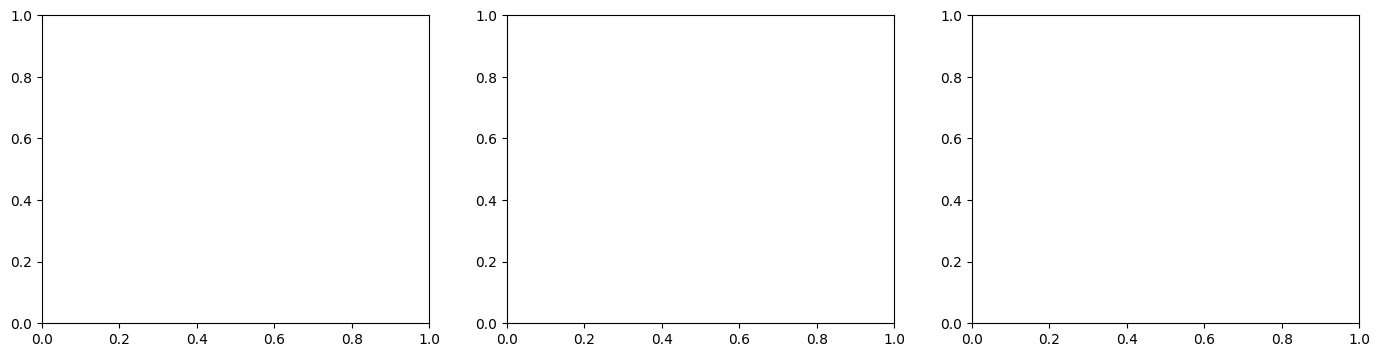

In [ ]:
# training curves
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(17, 4))
for h, nm in [(hist_base, 'Baseline CNN'), (hist_unet, 'U-Net L1')]:
    axs[0].plot(h['val'], label=f'{nm} val'); axs[0].plot(h['train'], '--', label=f'{nm} train')
axs[0].set_title('L1 loss (L1-trained models)'); axs[0].set_xlabel('epoch'); axs[0].legend()
axs[1].plot(hist_gan['G_adv'], label='G adversarial'); axs[1].plot(hist_gan['D'], label='D loss')
axs[1].set_title('GAN losses'); axs[1].set_xlabel('epoch'); axs[1].legend()
axs[2].plot(hist_gan['G_l1'], label='train L1'); axs[2].plot(hist_gan['val_l1'], label='val L1')
axs[2].set_title('GAN stage: L1 term'); axs[2].set_xlabel('epoch'); axs[2].legend()
plt.tight_layout(); plt.savefig(CKPT_DIR / 'training_curves.png', dpi=120); plt.show()

In [ ]:
try:
    import lpips
    lpips_fn = lpips.LPIPS(net='alex', verbose=False).to(DEVICE).eval()
except Exception as e:
    print('LPIPS unavailable, skipping it:', e)
    lpips_fn = None

def colorfulness(rgb):
    r, g, b = (rgb * 255).unbind(1)
    rg, yb = r - g, 0.5 * (r + g) - b
    std = torch.sqrt(rg.flatten(1).std(1) ** 2 + yb.flatten(1).std(1) ** 2)
    mean = torch.sqrt(rg.flatten(1).mean(1) ** 2 + yb.flatten(1).mean(1) ** 2)
    return std + 0.3 * mean

MODELS = {'Grayscale (no color)': None,
          'A: Baseline CNN (L1)': G_base,
          'B: U-Net ResNet34 (L1)': G_unet,
          'C: U-Net + PatchGAN': G_gan}

@torch.no_grad()
def evaluate(models, loader):
    keys = ['PSNR', 'SSIM', 'LPIPS', 'ab_MAE', 'Colorfulness']
    acc = {k: {m: [] for m in keys} for k in models}
    gt_col = []
    for rgb_u8 in tqdm(loader, desc='evaluating'):
        L, ab, rgb = prep(rgb_u8)
        gt_np = rgb.permute(0, 2, 3, 1).cpu().numpy()
        gt_col += colorfulness(rgb).tolist()
        for name, G in models.items():
            pred_ab = torch.zeros_like(ab) if G is None else G.eval()(L)
            pred = to_rgb(L, pred_ab)
            mse = ((pred - rgb) ** 2).flatten(1).mean(1).clamp_min(1e-10)
            acc[name]['PSNR'] += (10 * torch.log10(1 / mse)).tolist()
            pn = pred.permute(0, 2, 3, 1).cpu().numpy()
            acc[name]['SSIM'] += [ssim_fn(g, p, channel_axis=2, data_range=1.0) for g, p in zip(gt_np, pn)]
            if lpips_fn is not None:
                acc[name]['LPIPS'] += lpips_fn(pred * 2 - 1, rgb * 2 - 1).flatten().tolist()
            acc[name]['ab_MAE'] += (((pred_ab - ab).abs().flatten(1).mean(1)) * 110).tolist()
            acc[name]['Colorfulness'] += colorfulness(pred).tolist()
    df = pd.DataFrame({k: {m: (np.mean(v) if len(v) else np.nan) for m, v in d.items()} for k, d in acc.items()}).T
    return df, float(np.mean(gt_col))

results, gt_colorfulness = evaluate(MODELS, test_loader)
results = results.round(4)
results.to_csv(CKPT_DIR / 'results.csv')
print(f'Test images: {len(test_paths)}   |   Ground-truth colorfulness: {gt_colorfulness:.2f}')
results

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:02<00:00, 93.2MB/s]


evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

Test images: 474   |   Ground-truth colorfulness: 44.52


,PSNR,SSIM,LPIPS,ab_MAE,Colorfulness
Grayscale (no color),21.9004,0.9098,0.2388,10.8807,0.0034
A: Baseline CNN (L1),22.7860,0.9132,0.2116,9.6468,15.6903
B: U-Net ResNet34 (L1),23.4519,0.9165,0.1762,8.7564,24.1010
C: U-Net + PatchGAN,21.7283,0.8812,0.1966,10.5424,42.7023


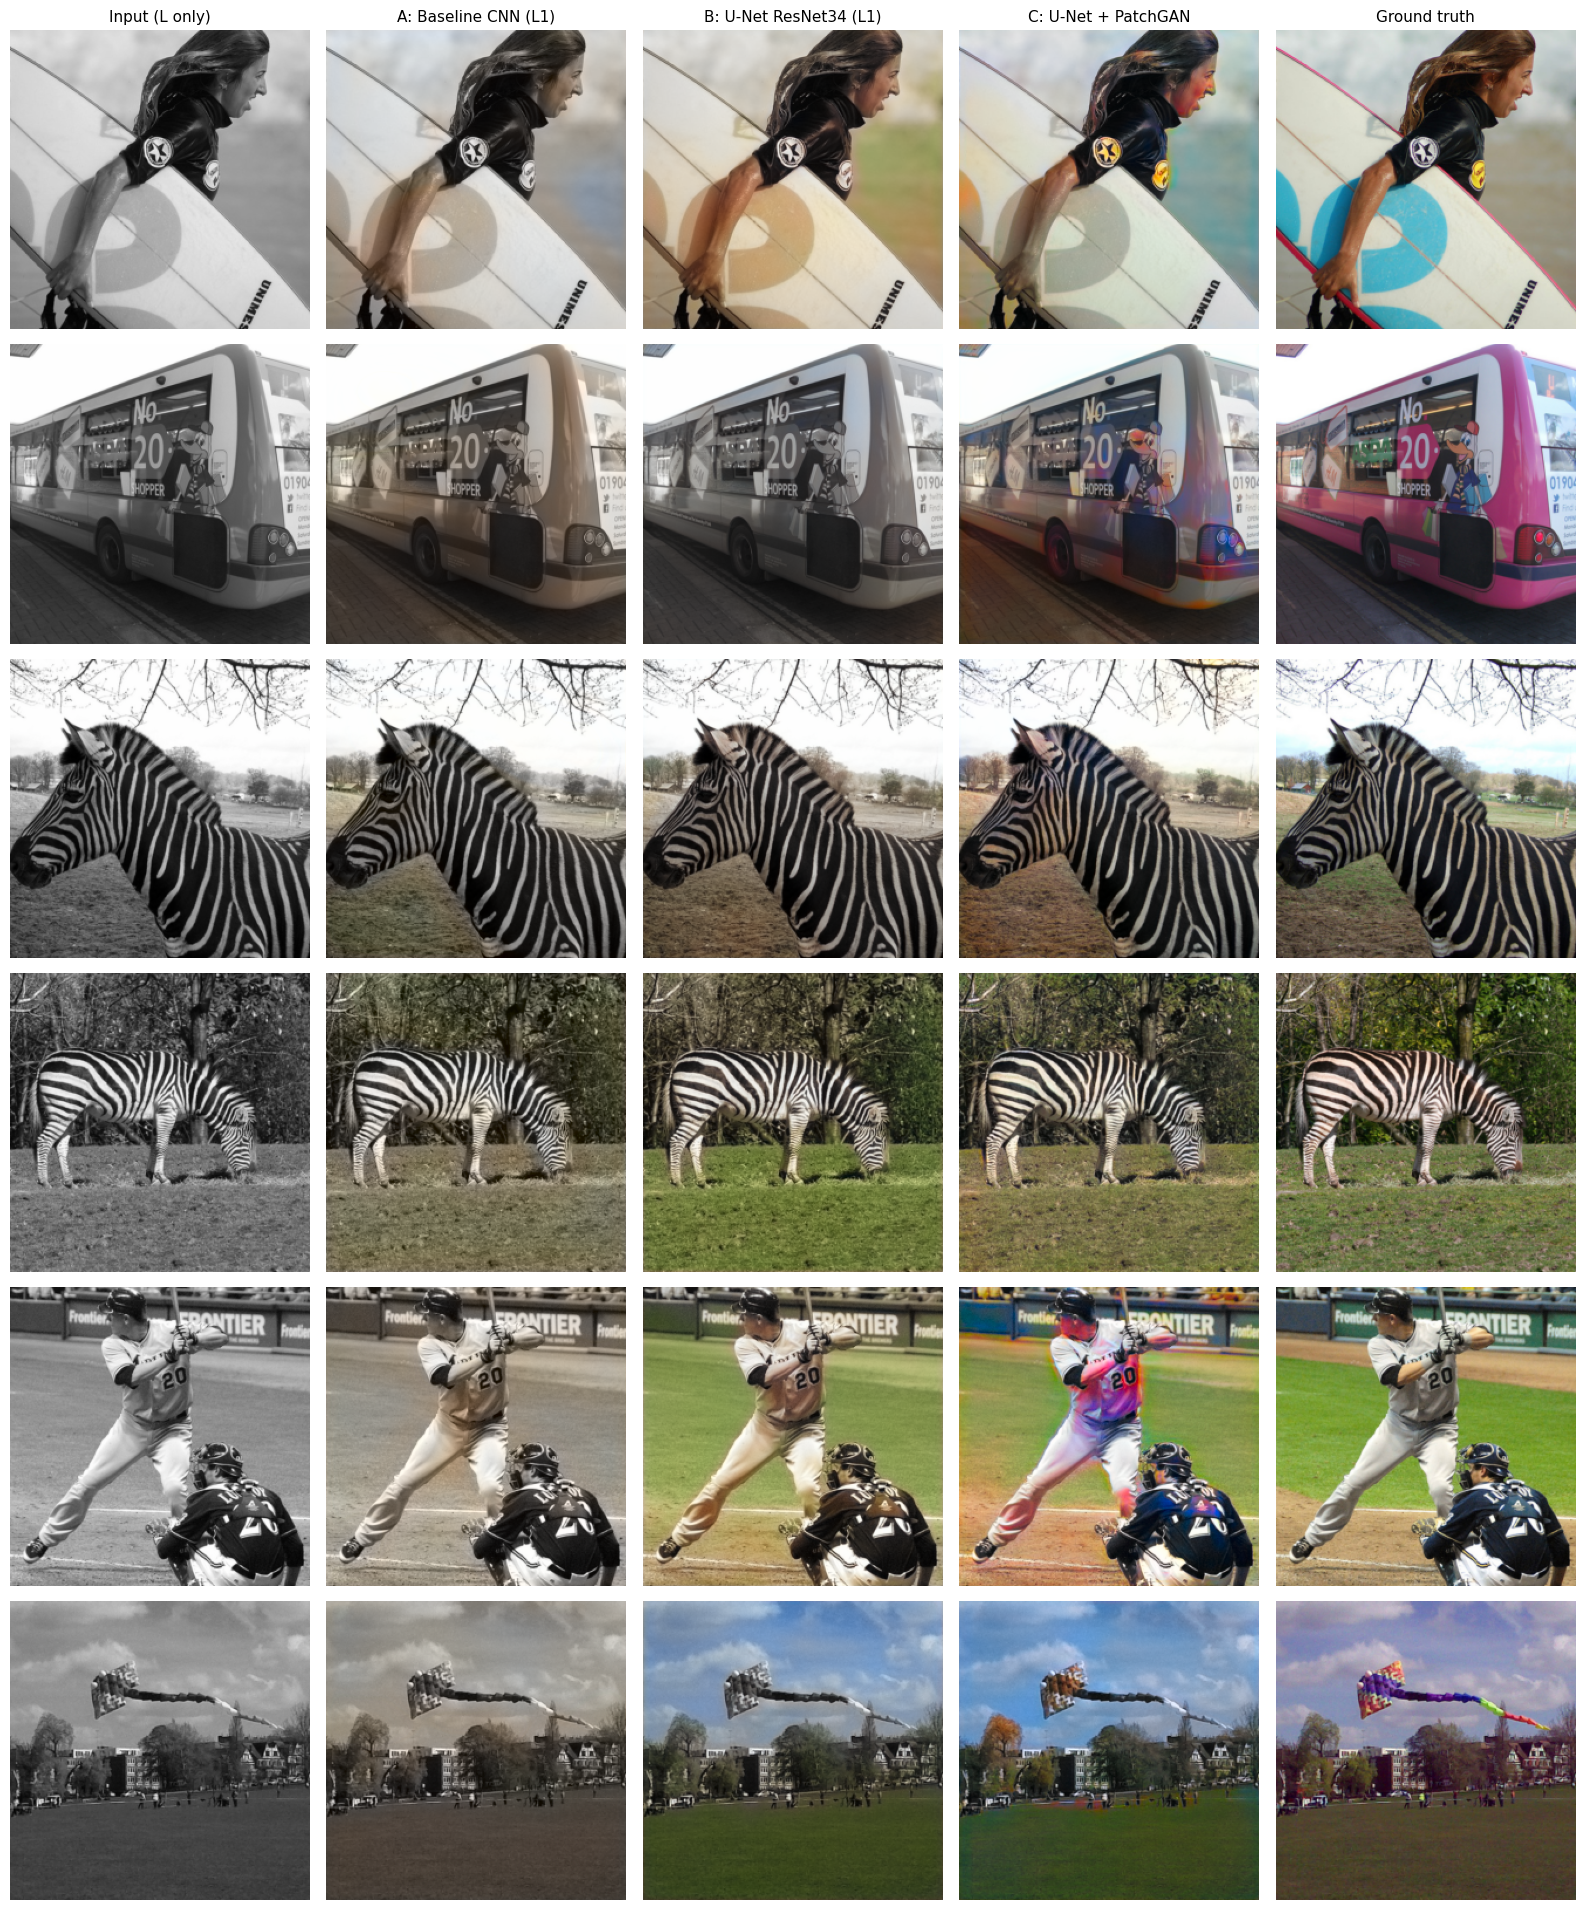

In [ ]:
@torch.no_grad()
def show_grid(models, loader, n=6, save_path=None):
    rgb_u8 = next(iter(loader))[:n]
    L, ab, rgb = prep(rgb_u8)
    cols = [('Input (L only)', to_rgb(L, torch.zeros_like(ab)))]
    cols += [(nm, to_rgb(L, G.eval()(L))) for nm, G in models.items() if G is not None]
    cols += [('Ground truth', rgb)]
    fig, axs = plt.subplots(len(L), len(cols), figsize=(3.2 * len(cols), 3.2 * len(L)))
    axs = np.atleast_2d(axs)
    for j, (title, imgs) in enumerate(cols):
        for i in range(len(L)):
            axs[i, j].imshow(imgs[i].permute(1, 2, 0).cpu().numpy()); axs[i, j].axis('off')
            if i == 0: axs[i, j].set_title(title, fontsize=11)
    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=110)
    plt.show()

show_grid(MODELS, test_loader, n=6, save_path=CKPT_DIR / 'qualitative_results.png')

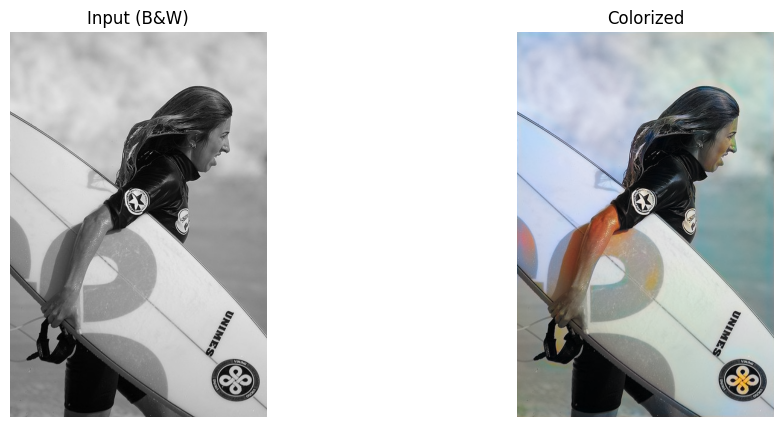

In [ ]:
@torch.no_grad()
def colorize_pil(img, G=None):
    G = (G if G is not None else G_gan).eval()
    img = img.convert('RGB')
    W, H = img.size
    if max(W, H) > 2048:
        s = 2048 / max(W, H); W, H = int(W * s), int(H * s); img = img.resize((W, H), Image.LANCZOS)
    x = torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)[None].float().div(255).to(DEVICE)
    L_full = rgb_to_lab(x)[:, :1]                                           # 0..100, full res
    L_small = F.interpolate(L_full / 50 - 1, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
    ab = G(L_small)
    ab_full = F.interpolate(ab, size=(H, W), mode='bicubic', align_corners=False).clamp(-1, 1)
    out = lab_to_rgb(torch.cat([L_full, ab_full * 110], 1))[0]
    return Image.fromarray((out.permute(1, 2, 0).cpu().numpy() * 255).round().astype(np.uint8))

# quick demo on a test image, converted to true grayscale first
demo_img = Image.open(test_paths[0]).convert('L').convert('RGB')
out_img = colorize_pil(demo_img)
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(demo_img); axs[0].set_title('Input (B&W)'); axs[1].imshow(out_img); axs[1].set_title('Colorized')
for a_ in axs: a_.axis('off')
plt.show()

In [ ]:
# Interactive web demo (gives a public link you can open on your phone / show an interviewer)
import gradio as gr
CHOICES = {'C: U-Net + PatchGAN': G_gan, 'B: U-Net (L1)': G_unet, 'A: Baseline CNN': G_base}
def _gradio_fn(img, model_name):
    return colorize_pil(img, CHOICES[model_name])
demo = gr.Interface(fn=_gradio_fn,
                    inputs=[gr.Image(type='pil', label='Upload a black & white photo'),
                            gr.Dropdown(list(CHOICES), value='C: U-Net + PatchGAN', label='Model')],
                    outputs=gr.Image(label='Colorized'),
                    title='B&W Image Colorization (Lab space, U-Net + PatchGAN)')
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4efa5d923844ea7cbb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
